In [1]:
# %pip install torch torchvision matplotlib

In [2]:
import os
# OpenMP 라이브러리가 두 번 불러와져도 멈추지 않게
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"   

import platform
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

if platform.system() == "Windows":
    plt.rcParams["font.family"] = "Malgun Gothic"
elif platform.system() == "Darwin":
    plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("사용 장치:", device)

사용 장치: cpu


100%|██████████| 170M/170M [13:23<00:00, 212kB/s]  


학습용: 50000 시험용: 10000


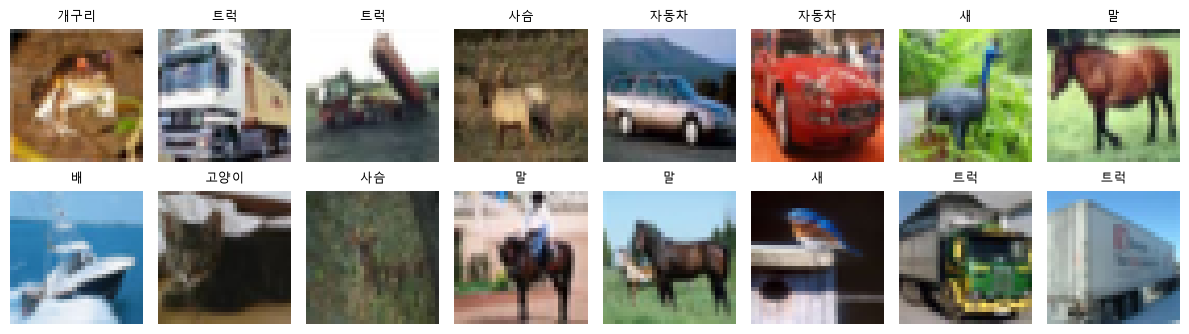

In [3]:
CLASSES = ["비행기", "자동차", "새", "고양이", "사슴", "개", "개구리", "말", "배", "트럭"]
MODEL_FILE = "cnn_cifar10.pt"

# 채널(빨강, 초록, 파랑)마다 평균과 표준편차로 맞춘다 (CIFAR-10 학습용 사진 전체에서 구한 값)
MEAN = (0.4914, 0.4822, 0.4465)
STD = (0.2470, 0.2435, 0.2616)


# ---------- 1. 데이터 선택 + 2. 사전 준비 ----------
# 학습용: 데이터 늘리기(증강)를 한다. 에포크마다 같은 사진이 조금씩 다르게 들어간다
train_transform = transforms.Compose([
    # 부분
    transforms.RandomCrop(32, padding=4),     # 가장자리를 4칸 늘린 뒤 32x32를 무작위 위치에서 잘라낸다 (조금 옮기기)
    # 좌우 반전
    transforms.RandomHorizontalFlip(),        # 50% 확률로 좌우 뒤집기
    # 확대 또는 축소할 수 있음. 여기에는 적용 안한 상태(이미지가 작아서)    
    transforms.ToTensor(),                    # 0~255 → 0~1, 모양 (3, 32, 32)
    transforms.Normalize(MEAN, STD),
])
# 검증용, 시험용: 증강하지 않는다 (채점은 원래 사진으로)
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

train_full = datasets.CIFAR10("data", train=True, download=True, transform=train_transform)
valid_full = datasets.CIFAR10("data", train=True, download=True, transform=test_transform)   # 같은 사진, 다른 사전 준비
test_data = datasets.CIFAR10("data", train=False, download=True, transform=test_transform)
print("학습용:", len(train_full), "시험용:", len(test_data))

# 데이터 먼저 보기 (사전 준비 전 원래 사진)
raw = datasets.CIFAR10("data", train=True, download=True)
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for i, ax in enumerate(axes.flat):
    img, lbl = raw[i]
    ax.imshow(img)
    ax.set_title(CLASSES[lbl], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [4]:
# ---------- 3. 훈련, 검증, 테스트 분리 ----------
# 학습용 5만 장 중 5천 장을 검증용으로. 같은 번호의 사진을 증강 있는 것/없는 것에서 각각 꺼낸다
indices = torch.randperm(len(train_full), generator=torch.Generator().manual_seed(42)).tolist()
train_data = Subset(train_full, indices[5000:])
valid_data = Subset(valid_full, indices[:5000])

train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
valid_loader = DataLoader(valid_data, batch_size=256)
test_loader = DataLoader(test_data, batch_size=256)
print("학습:", len(train_data), "검증:", len(valid_data), "시험:", len(test_data))

학습: 45000 검증: 5000 시험: 10000


In [5]:
# ---------- 4. 학습 ----------
def conv_block(in_ch, out_ch):
    """합성곱 묶음: Conv → BatchNorm → ReLU → Conv → BatchNorm → ReLU → 풀링(크기 절반)"""
    return nn.Sequential(
        # 특징 찾음
        nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
        # 정규화 
        nn.BatchNorm2d(out_ch),
        # 활성화 함수
        nn.ReLU(),
        
        nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(),
        # 특징 압축
        nn.MaxPool2d(2),
    )


class CifarCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            # 3 : 칼라이미지여서 r,g,b 3개
            conv_block(3, 32),     # (3, 32, 32)  → (32, 16, 16)   선, 색 경계
            conv_block(32, 64),    # (32, 16, 16) → (64, 8, 8)     모서리, 무늬
            conv_block(64, 128),   # (64, 8, 8)   → (128, 4, 4)    바퀴, 귀, 날개 같은 부분
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),          # (128, 4, 4) → 2048
            nn.Dropout(0.3),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 10),    # 출력층 10
        )

    def forward(self, x):
        return self.classifier(self.features(x))


model = CifarCNN().to(device)
print(model)
print("학습할 숫자:", sum(p.numel() for p in model.parameters()))

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)


def accuracy(loader):
    model.eval()   # BatchNorm, Dropout이 예측용으로 바뀐다 (이 모델에서는 꼭 필요하다)
    correct = total = 0
    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            correct += (model(X).argmax(dim=1) == y).sum().item()
            total += len(y)
    return correct / total


EPOCHS = 10   # 15~20으로 늘리면 조금 더 오른다 (시간도 그만큼 더 걸린다)
best_valid = 0
for epoch in range(1, EPOCHS + 1):
    model.train()   # BatchNorm, Dropout이 학습용으로 바뀐다
    total_loss = 0
    for X, y in train_loader:
        X, y = X.to(device), y.to(device)
        loss = loss_fn(model(X), y)      # 1. 순전파 2. 손실
        optimizer.zero_grad()
        loss.backward()                  # 3. 역전파
        optimizer.step()                 # 4. 수정
        total_loss += loss.item() * len(y)

    valid_acc = accuracy(valid_loader)
    print(f"에포크 {epoch:2}: 학습 손실 {total_loss / len(train_data):.4f}, 검증 정확도 {valid_acc:.1%}")
    if valid_acc > best_valid:
        best_valid = valid_acc
        torch.save(model.state_dict(), MODEL_FILE)
        print("  → 지금까지 가장 좋아서 저장했습니다")

CifarCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU()
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU()
      (6): MaxPool2d(kernel_size=2, stride=

In [6]:
# ---------- 5. 평가 ----------
model.load_state_dict(torch.load(MODEL_FILE))
print(f"\n시험 정확도: {accuracy(test_loader):.1%}  (사진 1만 장, 학습에 한 번도 안 쓴 데이터)")

correct = [0] * 10
total = [0] * 10
model.eval()
with torch.no_grad():
    for X, y in test_loader:
        pred = model(X.to(device)).argmax(dim=1).cpu()
        for p, t in zip(pred, y):
            total[t] += 1
            correct[t] += int(p == t)
print("\n종류별 정확도")
for i, name in enumerate(CLASSES):
    print(f"  {name:4}: {correct[i] / total[i]:.1%}")


시험 정확도: 80.7%  (사진 1만 장, 학습에 한 번도 안 쓴 데이터)

종류별 정확도
  비행기 : 75.9%
  자동차 : 88.7%
  새   : 59.1%
  고양이 : 68.0%
  사슴  : 74.5%
  개   : 83.7%
  개구리 : 89.8%
  말   : 81.6%
  배   : 93.8%
  트럭  : 92.1%


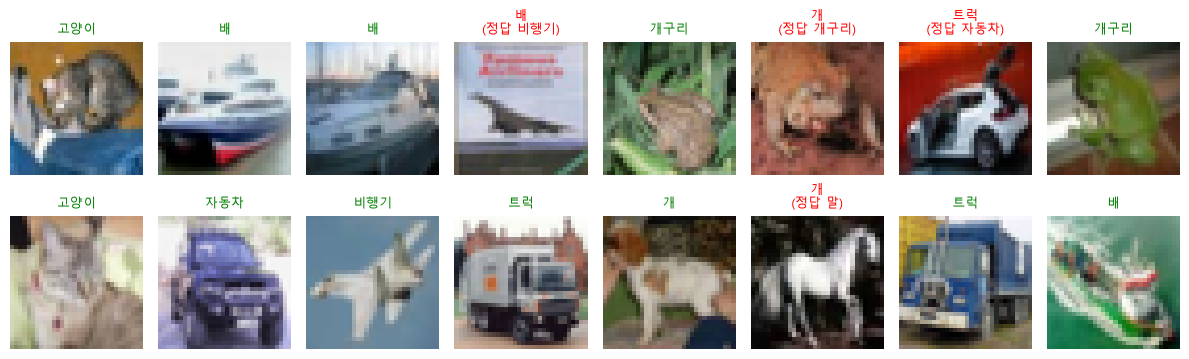

In [7]:
# ---------- 6. 예측 ----------
def to_image(t):
    """사전 준비(Normalize)를 되돌려서 그림으로 볼 수 있게 한다"""
    img = t.permute(1, 2, 0) * torch.tensor(STD) + torch.tensor(MEAN)
    return img.clamp(0, 1)


X_test, y_test = next(iter(test_loader))
with torch.no_grad():
    pred = model(X_test.to(device)).argmax(dim=1).cpu()

fig, axes = plt.subplots(2, 8, figsize=(12, 3.8))
for i, ax in enumerate(axes.flat):
    ax.imshow(to_image(X_test[i]))
    ok = pred[i] == y_test[i]
    title = CLASSES[pred[i]] if ok else f"{CLASSES[pred[i]]}\n(정답 {CLASSES[y_test[i]]})"
    ax.set_title(title, color="green" if ok else "red", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()